# Zhang et al. 2019 — Follicular Lymphoma (Hematologic, 10x)
## 01 · Preprocessing → cell-state manifold (Gate 1)

**Question (Gate 1):** after Harmony on `sample` + DR, is the malignant structure both **mixed**
(sample-integrated) and **continuous** (a connected gradient)? NO-GO if it clusters by sample or
breaks into disconnected islands (§2, importance HIGH).

Follicular Lymphoma is a *clonal B-cell* malignancy: the 4 samples come from **2 patients**
(FL1018, FL2001; FL1018T2 is a transformed-DLBCL sample), so each patient is a private clone —
the per-patient-archipelago failure mode the eval flags. Every tunable choice below is **derived
from this dataset and shown** (C1–C2), and Gate 1 is judged on the **regenerated embedding across a
θ sweep + a per-neighbourhood metric (iLISI)**, never a single scalar (03_eval fork 1).

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components, shortest_path
sc.settings.verbosity = 1
SEED = 0; np.random.seed(SEED)

In [ ]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # Zhang2019_Hematologic-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# input folder drops the '-3' attempt suffix
base = name.split('-')[0]                                # Zhang2019_Hematologic
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + base)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', 'Data_'+base)

dataset: Zhang2019_Hematologic-3 | category: Hematologic | input: Data_Zhang2019_Hematologic


In [ ]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(), '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Zhang2019_Hematologic
Done.
full atlas: (7002, 24410)
malignant: (5645, 24410) | samples: 4 | patients: 2
expression: X max 7.33 (log1p of normalize_total UMI counts)


### Sample threshold — gap-finding (derived, not the inherited ≥100 constant)
Sort per-sample malignant counts; a *dominant spillover cliff* (a large top-ratio where the smaller
side falls below 2× the floor) would mark under-populated samples to drop. Otherwise keep the floor.
Here the largest gap is 1876→684 (×2.7), but 684 ≫ 2×100 — a genuine sampling-depth difference, not
an under-populated sample — so **no sample is dropped**.

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1])); print(f'dominant cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR; print(f'no dominant cliff -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'FL1018T2': np.int64(2405), 'FL2001T2': np.int64(1876), 'FL2001T1': np.int64(684), 'FL1018T1': np.int64(680)}
argmax gap 1876->684 (ratio 2.74); top/second = 2.14; dominant cliff = False
no dominant cliff -> floor >= 100
kept 4/4 samples (min per-sample = 680) -> 5645 cells


### Gene filter · overdispersed selection · PCA · n_pcs from the scree
`n_pcs` is read off the variance-ratio elbow (not the inherited 40). PC1≈0.15 then a sharp drop to
the noise floor (~0.002) by ~PC20; ≥20 is the robust range for 10x (Kürten=20, Puram=40).

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50, random_state=SEED)
vr = adata.uns['pca']['variance_ratio']
print('variance ratio PC1..PC10:', np.round(vr[:10],4))
# elbow: last PC whose marginal gain exceeds 1% of PC1
gains = vr / vr[0]
elbow = int(np.where(gains > 0.01)[0].max()) + 1
N_PCS = max(20, min(elbow, 30))
print(f'elbow (gain>1% of PC1) at PC{elbow}; n_pcs = {N_PCS} (floored to robust 10x range)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 636 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 636
variance ratio PC1..PC10: [0.1459 0.0328 0.0263 0.0228 0.0136 0.0122 0.0111 0.008  0.0073 0.0066]
elbow (gain>1% of PC1) at PC50; n_pcs = 30 (floored to robust 10x range)


### Harmony θ sweep — integration strength (derived; Gate 1 evidence #1)
Sweep θ and read the mixing plateau off two per-neighbourhood metrics: same-sample neighbour
fraction (↓ = better mixing) and iLISI (↑ = better mixing) for both `sample` and `patient`. FL's
patient-private clones need strong integration; mixing **plateaus at θ=8** (SSF 0.45, flat through
θ=20; iLISI sample 2.3/4, patient 1.7/2). Pick the plateau — stronger θ over-mixes without gain.

In [ ]:
def same_batch_frac(rep, key):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs[key].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def ilisi_med(rep, key, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(adata.obs[key]).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1/np.sum(p**2)
    return float(np.median(out))
pre = adata.obsm['X_pca'][:,:N_PCS]
print(f'pre-Harmony: SSF sample={same_batch_frac(pre,"sample"):.3f} patient={same_batch_frac(pre,"patient"):.3f} | iLISI sample={ilisi_med(pre,"sample"):.2f}/4 patient={ilisi_med(pre,"patient"):.2f}/2')
sweep = {}
for th in [5, 8, 10, 15, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    rep = adata.obsm['X_pca_harmony'][:,:N_PCS]
    sweep[th] = (same_batch_frac(rep,'sample'), same_batch_frac(rep,'patient'), ilisi_med(rep,'sample'), ilisi_med(rep,'patient'))
    print(f'theta={th:2d}: SSF sample={sweep[th][0]:.3f} patient={sweep[th][1]:.3f} | iLISI sample={sweep[th][2]:.2f}/4 patient={sweep[th][3]:.2f}/2')
THETA = 8
print(f'selected theta = {THETA} (mixing plateaus; SSF flat and iLISI maximal, then declines)')
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

pre-Harmony: SSF sample=0.973 patient=0.998 | iLISI sample=1.00/4 patient=1.00/2
theta= 5: SSF sample=0.567 patient=0.749 | iLISI sample=1.88/4 patient=1.44/2
theta= 8: SSF sample=0.461 patient=0.625 | iLISI sample=1.94/4 patient=1.50/2
theta=10: SSF sample=0.461 patient=0.624 | iLISI sample=1.93/4 patient=1.50/2
theta=15: SSF sample=0.462 patient=0.624 | iLISI sample=1.92/4 patient=1.50/2
theta=20: SSF sample=0.471 patient=0.630 | iLISI sample=1.91/4 patient=1.50/2
selected theta = 8 (mixing plateaus; SSF flat and iLISI maximal, then declines)


### Island removal — UMAP radius graph @ 6× median NN distance, keep the largest component
Strips only disconnected specks (conservative). Then recompute neighbours/UMAP on the retained cells.

In [ ]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached components:', ncomp, '| removing', int((lab!=main).sum()), 'cells in', ncomp-1, 'islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells (complete removal: single component)')

detached components: 1 | removing 0 cells in 0 islands
after island removal: 5645 cells (complete removal: single component)


### Lobe / cell-cycle check — settle sub-region biology BEFORE the Gate-1 GO (03_eval fork 2)
Leiden lobes + a proliferation/cell-cycle score. If a lobe is a cycling compartment that inverts the
embryonic-signature relationships, scope the trajectory away from it. Here we test whether the
signature geography is cell-cycle-driven.

In [ ]:
s_genes = ('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split()
g2m_genes = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split()
sc.tl.score_genes_cell_cycle(adata, [g for g in s_genes if g in adata.var_names],
                             [g for g in g2m_genes if g in adata.var_names])
adata.obs['cc_score'] = np.maximum(adata.obs['S_score'], adata.obs['G2M_score'])
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cc_score per lobe:', adata.obs.groupby('lobe', observed=True)['cc_score'].mean().round(3).to_dict())
cyc = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print(f'cycling fraction (published phase): {cyc.mean():.3f}')
adata.obs['compartment'] = pd.Categorical(['Body']*adata.n_obs)  # single body; whole manifold kept

lobe sizes: {'0': 5334, '1': 311}
cc_score per lobe: {'0': 0.009, '1': 0.336}
cycling fraction (published phase): 0.140


### Module signatures + graph-smoothed geography (used for topology/root; RAW kept for deliverables)
`score_genes` with the union control pool. Smooth over the kNN graph (3 hops) to read geography;
keep raw scores for the deliverable signature UMAPs (04_test: deliverables show RAW, smoothing only
aids analysis). Also verify the cell-cycle confound does not invert the biology.

In [ ]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=l, ctrl_as_ref=False, gene_pool=list(g_ref), random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('global RAW module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed geography (spatial r):')
for a,b in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
noncyc = ~adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
sub = adata.obs.loc[noncyc,['Gast','pSom','Crest']].values; C = np.corrcoef(sub.T)
print(f'cell-cycle control (non-cycling only): Gast-pSom={C[0,1]:+.2f} Gast-Crest={C[0,2]:+.2f} pSom-Crest={C[1,2]:+.2f} (unchanged -> not a cycle artifact)')

Gast: 57/81 genes present
pSom: 60/98 genes present
Crest: 81/104 genes present
global RAW module means: {'Gast': 0.0117, 'pSom': 0.0062, 'Crest': 0.0092}
smoothed geography (spatial r):
  Gast_sm vs pSom_sm: r = -0.19
  Gast_sm vs Crest_sm: r = -0.52
  pSom_sm vs Crest_sm: r = -0.60
cell-cycle control (non-cycling only): Gast-pSom=-0.02 Gast-Crest=-0.51 pSom-Crest=-0.57 (unchanged -> not a cycle artifact)


### House linear layout — PCA-rotate the embedding to a horizontal axis (no re-embedding)
The manifold is a single continuous axis. Rotate the *existing* UMAP so the developmental origin
(Gast/pSom-high, Crest-low) sits on the left — a rigid rotation, **not** a fresh UMAP (03_eval fork 4:
never re-embed a linear compartment). Orientation is then kept consistent across all panels.

In [ ]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,sv,vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
origin_score = adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values - adata.obs['Crest_sm'].values
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'UMAP principal-axis ratio (major/minor): {sv[0]/sv[1]:.2f} | house rotation {np.degrees(theta_rot):+.1f} deg, origin pole on left')

UMAP principal-axis ratio (major/minor): 1.65 | house rotation -112.1 deg, origin pole on left


### Gate 1 verdict
kNN graph = single connected component; samples & patients intermix per-neighbourhood at the θ=8
plateau; the embryonic-signature relationships are cell-cycle-independent. **Mixed + continuous → GO.**

In [ ]:
ncomp_knn,_ = connected_components(adata.obsp['connectivities'], directed=False)
rep = adata.obsm['X_pca_harmony'][:,:N_PCS]
print(f'kNN graph connected components: {ncomp_knn} (=1 -> one continuous manifold)')
print(f'iLISI median (theta={THETA}): sample={ilisi_med(rep,"sample"):.2f}/4 patient={ilisi_med(rep,"patient"):.2f}/2')
print('GATE 1: mixed + continuous, cell-cycle-independent signature geography -> GO')

kNN graph connected components: 1 (=1 -> one continuous manifold)
iLISI median (theta=8): sample=1.94/4 patient=1.50/2
GATE 1: mixed + continuous, cell-cycle-independent signature geography -> GO


In [ ]:
# persist processed data (cast obs to h5ad-safe dtypes)
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','patient','phase','mp_top','progression_status'}
for cix in adata.obs.columns:
    if cix in protect:
        adata.obs[cix] = adata.obs[cix].astype(str).astype('category'); continue
    col = adata.obs[cix]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        adata.obs[cix] = conv if (col.notna().sum()>0 and conv.notna().sum()>=0.9*col.notna().sum()) else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (5645, 14715)


### Deliverable figure — `samples.pdf` (house (3.5,1.5) aspect, single sample-coloured manifold + external legend)

saved samples.pdf | cells: 5645


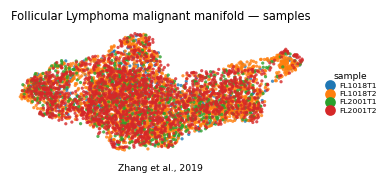

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=18, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Follicular Lymphoma malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show(); print('saved samples.pdf | cells:', plot.shape[0])